In [1]:
import pandas as pd
import sklearn
print("Setup works! scikit-learn version:", sklearn.__version__)

Setup works! scikit-learn version: 1.9.1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
print("Shape (rows, columns):", df.shape)
print()
print("Missing values per column:")
print(df.isnull().sum())

Shape (rows, columns): (20640, 9)

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [3]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


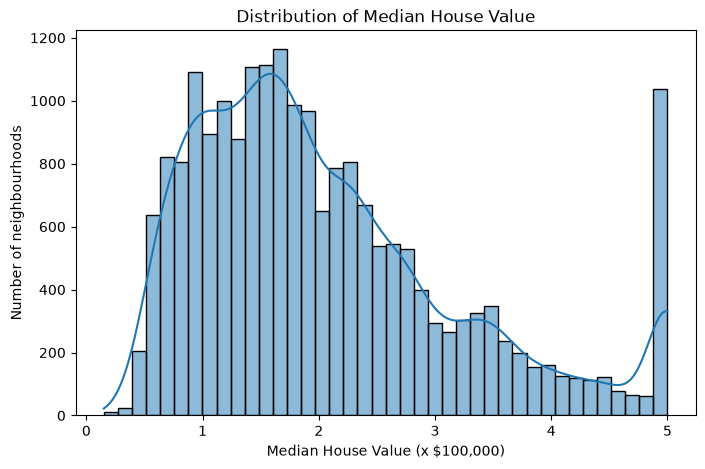

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value (x $100,000)")
plt.ylabel("Number of neighbourhoods")
plt.show()

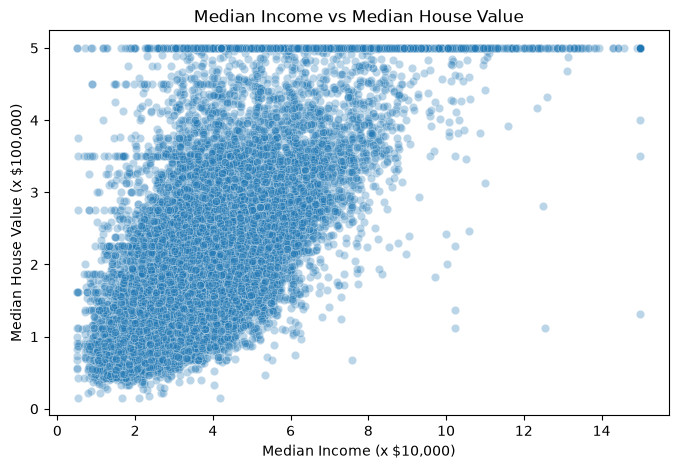

In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="MedInc", y="MedHouseVal", data=df, alpha=0.3)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (x $10,000)")
plt.ylabel("Median House Value (x $100,000)")
plt.show()

In [6]:
df.info()
print()
print("Duplicate rows:", df.duplicated().sum())
print("Capped prices (= 5.0):", (df["MedHouseVal"] >= 5.0).sum())
print("Rows with AveRooms > 20:", (df["AveRooms"] > 20).sum())
print("Rows with AveBedrms > 5:", (df["AveBedrms"] > 5).sum())
print("Rows with AveOccup > 10:", (df["AveOccup"] > 10).sum())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Duplicate rows: 0
Capped prices (= 5.0): 992
Rows with AveRooms > 20: 69
Rows with AveBedrms > 5: 45
Rows with AveOccup > 10: 37


In [7]:
df_clean = df[
    (df["MedHouseVal"] < 5.0) &
    (df["AveRooms"] <= 20) &
    (df["AveBedrms"] <= 5) &
    (df["AveOccup"] <= 10)
].copy()

print("Before:", df.shape)
print("After: ", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("Max price now:", df_clean["MedHouseVal"].max())

Before: (20640, 9)
After:  (19545, 9)
Rows removed: 1095
Max price now: 4.991


In [8]:
corr = df_clean.corr()

print(corr["MedHouseVal"].sort_values(ascending=False))

MedHouseVal    1.000000
MedInc         0.648399
AveRooms       0.206515
HouseAge       0.064611
Population     0.012986
Longitude     -0.045565
AveBedrms     -0.107273
Latitude      -0.149099
AveOccup      -0.242940
Name: MedHouseVal, dtype: float64


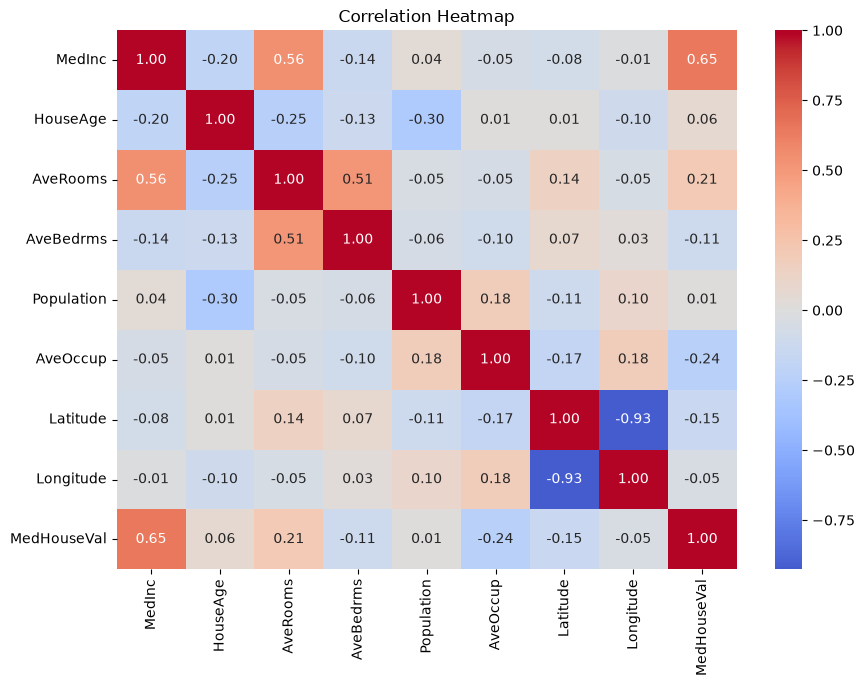

In [9]:
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms",
            "AveOccup", "Latitude", "Longitude"]

X = df_clean[features]
y = df_clean["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])
print("Features used:", list(X.columns))

Training rows: 15636
Testing rows:  3909
Features used: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'AveOccup', 'Latitude', 'Longitude']


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled training features (should be ~0):")
print(X_train_scaled.mean(axis=0).round(3))
print()
print("Std of scaled training features (should be ~1):")
print(X_train_scaled.std(axis=0).round(3))

Mean of scaled training features (should be ~0):
[ 0.  0.  0. -0.  0.  0.  0.]

Std of scaled training features (should be ~1):
[1. 1. 1. 1. 1. 1. 1.]
